In [ ]:
import numpy as np
import random
import matplotlib.pyplot as plt
import pandas as pd

from collections import defaultdict

random.seed(42)
np.random.seed(42)

print("RESCUE-SWARM initialized successfully!")

RESCUE-SWARM initialized successfully!


In [ ]:
GRID_SIZE = 8

# Starting positions of rescue agents
START_POSITIONS = {
    0: (0, 0),
    1: (7, 7)
}

# Victim locations
VICTIMS = {
    0: (1, 5),
    1: (3, 2),
    2: (5, 6),
    3: (6, 1)
}

# Assign two victims to each agent
ASSIGNMENTS = {
    0: [0, 1],
    1: [2, 3]
}

# Obstacles
OBSTACLES = {
    (1, 1), (2, 1), (3, 1),
    (4, 3), (4, 4),
    (2, 5), (3, 5),
    (6, 4)
}

# Hazardous areas
HAZARDS = {
    (2, 3), (5, 3), (6, 6)
}

# Actions: Up, Down, Left, Right
ACTIONS = {
    0: (-1, 0),
    1: (1, 0),
    2: (0, -1),
    3: (0, 1)
}

ACTION_NAMES = {
    0: "Up",
    1: "Down",
    2: "Left",
    3: "Right"
}

print("Grid environment created!")
print("Agents:", len(START_POSITIONS))
print("Victims:", len(VICTIMS))
print("Obstacles:", len(OBSTACLES))
print("Hazards:", len(HAZARDS))

Grid environment created!
Agents: 2
Victims: 4
Obstacles: 8
Hazards: 3


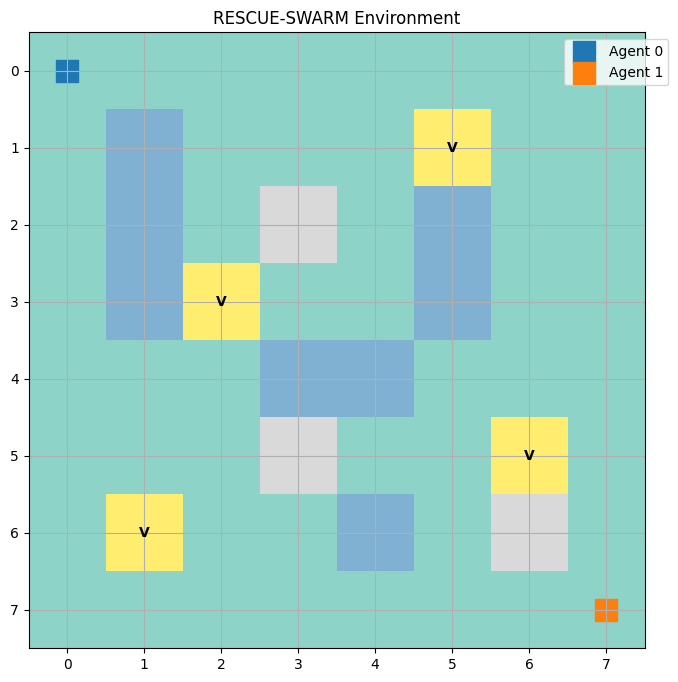

In [ ]:
def draw_environment(
    positions=None,
    rescued=None,
    trajectories=None,
    title="RESCUE-SWARM Environment"
):

    if positions is None:
        positions = START_POSITIONS

    if rescued is None:
        rescued = set()

    grid = np.zeros((GRID_SIZE, GRID_SIZE))

    for x, y in OBSTACLES:
        grid[x, y] = 1

    for x, y in HAZARDS:
        grid[x, y] = 2

    for victim, (x, y) in VICTIMS.items():
        if victim not in rescued:
            grid[x, y] = 3

    plt.figure(figsize=(8, 8))

    plt.imshow(grid, cmap="Set3", vmin=0, vmax=3)

    for agent, (x, y) in positions.items():
        plt.scatter(y, x, marker="s", s=250, label=f"Agent {agent}")

    for victim, (x, y) in VICTIMS.items():
        if victim not in rescued:
            plt.text(y, x, "V", ha="center", va="center",
                     fontweight="bold")

    if trajectories:
        for agent, path in trajectories.items():
            if path:
                xs = [p[1] for p in path]
                ys = [p[0] for p in path]
                plt.plot(xs, ys, marker=".", label=f"Path {agent}")

    plt.xticks(range(GRID_SIZE))
    plt.yticks(range(GRID_SIZE))
    plt.grid(True)
    plt.title(title)
    plt.legend(bbox_to_anchor=(1.05, 1))
    plt.show()


draw_environment()

In [ ]:
#Exercise 2 – States, Actions and Rewards
REWARDS = {
    "rescue": 30,
    "hazard": -10,
    "collision": -8,
    "invalid": -4,
    "movement": -1
}

ALPHA = 0.1       # Learning rate
GAMMA = 0.9       # Discount factor
EPSILON = 1.0     # Initial exploration rate
EPSILON_MIN = 0.05
EPSILON_DECAY = 0.995

def get_state(position, target):

    return (
        position[0],
        position[1],
        target[0],
        target[1]
    )


def get_next_target(agent, rescued):

    for victim_id in ASSIGNMENTS[agent]:

        if victim_id not in rescued:
            return VICTIMS[victim_id]

    return None

In [ ]:
#Implement the environment movement
def environment_step(
    agent,
    action,
    positions,
    rescued
):

    x, y = positions[agent]

    dx, dy = ACTIONS[action]

    new_position = (x + dx, y + dy)

    # Invalid boundary or obstacle
    if (
        not (0 <= new_position[0] < GRID_SIZE)
        or not (0 <= new_position[1] < GRID_SIZE)
        or new_position in OBSTACLES
    ):

        return REWARDS["invalid"], False, False

    # Collision with another agent
    other_agent = 1 - agent

    if new_position == positions[other_agent]:

        return REWARDS["collision"], False, True

    # Update position
    positions[agent] = new_position

    reward = REWARDS["movement"]

    # Hazard penalty
    if new_position in HAZARDS:
        reward += REWARDS["hazard"]

    # Check victim rescue
    rescued_now = False

    for victim_id in ASSIGNMENTS[agent]:

        if (
            victim_id not in rescued
            and new_position == VICTIMS[victim_id]
        ):

            rescued.add(victim_id)

            reward += REWARDS["rescue"]

            rescued_now = True

            break

    return reward, rescued_now, False

In [ ]:
#Exercise 3 – Independent Q-Learning
def choose_action(q_table, state, epsilon):

    if random.random() < epsilon:
        return random.choice(list(ACTIONS.keys()))

    return int(np.argmax(q_table[state]))


def update_q(
    q_table,
    state,
    action,
    reward,
    next_state,
    done
):

    old_value = q_table[state][action]

    if done:
        future_value = 0

    else:
        future_value = np.max(q_table[next_state])

    new_value = old_value + ALPHA * (
        reward + GAMMA * future_value - old_value
    )

    q_table[state][action] = new_value

In [ ]:
def train_independent(episodes=2500):

    q_tables = {
        0: defaultdict(lambda: np.zeros(4)),
        1: defaultdict(lambda: np.zeros(4))
    }

    episode_rewards = []
    rescue_history = []
    time_history = []
    collision_history = []

    epsilon = EPSILON

    for episode in range(episodes):

        positions = START_POSITIONS.copy()
        rescued = set()

        total_reward = 0
        collisions = 0
        steps = 0

        while len(rescued) < len(VICTIMS) and steps < 120:

            for agent in [0, 1]:

                target = get_next_target(agent, rescued)

                if target is None:
                    continue

                state = get_state(
                    positions[agent],
                    target
                )

                action = choose_action(
                    q_tables[agent],
                    state,
                    epsilon
                )

                reward, rescued_now, collision = environment_step(
                    agent,
                    action,
                    positions,
                    rescued
                )

                collisions += int(collision)

                total_reward += reward

                steps += 1

                next_target = get_next_target(
                    agent,
                    rescued
                )

                done = (
                    next_target is None
                    or len(rescued) == len(VICTIMS)
                    or steps >= 120
                )

                if done:
                    next_state = state

                else:
                    next_state = get_state(
                        positions[agent],
                        next_target
                    )

                update_q(
                    q_tables[agent],
                    state,
                    action,
                    reward,
                    next_state,
                    done
                )

                if len(rescued) == len(VICTIMS) or steps >= 120:
                    break

        episode_rewards.append(total_reward)
        rescue_history.append(len(rescued))
        time_history.append(steps)
        collision_history.append(collisions)

        epsilon = max(
            EPSILON_MIN,
            epsilon * EPSILON_DECAY
        )

    return (
        q_tables,
        episode_rewards,
        rescue_history,
        time_history,
        collision_history
    )

In [ ]:
independent_results = train_independent(2500)

(
    independent_q,
    independent_rewards,
    independent_rescues,
    independent_times,
    independent_collisions
) = independent_results

print("Independent Q-Learning completed!")
print("Agent 0 Q-states:", len(independent_q[0]))
print("Agent 1 Q-states:", len(independent_q[1]))
print("Average reward in last 100 episodes:",
      round(np.mean(independent_rewards[-100:]), 2))

Independent Q-Learning completed!
Agent 0 Q-states: 110
Agent 1 Q-states: 110
Average reward in last 100 episodes: 95.04


In [ ]:
#Exercise 4 – Cooperative Learning
def train_cooperative(episodes=2500):

    # Shared Q-table
    shared_q = defaultdict(lambda: np.zeros(4))

    episode_rewards = []
    rescue_history = []
    time_history = []
    collision_history = []

    epsilon = EPSILON

    for episode in range(episodes):

        positions = START_POSITIONS.copy()
        rescued = set()

        total_reward = 0
        collisions = 0
        steps = 0

        while len(rescued) < len(VICTIMS) and steps < 120:

            for agent in [0, 1]:

                target = get_next_target(agent, rescued)

                if target is None:
                    continue

                state = get_state(
                    positions[agent],
                    target
                )

                # Both agents use the shared Q-table
                action = choose_action(
                    shared_q,
                    state,
                    epsilon
                )

                reward, rescued_now, collision = environment_step(
                    agent,
                    action,
                    positions,
                    rescued
                )

                collisions += int(collision)

                total_reward += reward

                steps += 1

                # Shared team reward
                team_reward = reward

                if rescued_now:
                    team_reward += 5

                next_target = get_next_target(
                    agent,
                    rescued
                )

                done = (
                    next_target is None
                    or len(rescued) == len(VICTIMS)
                    or steps >= 120
                )

                if done:
                    next_state = state

                else:
                    next_state = get_state(
                        positions[agent],
                        next_target
                    )

                update_q(
                    shared_q,
                    state,
                    action,
                    team_reward,
                    next_state,
                    done
                )

                if len(rescued) == len(VICTIMS) or steps >= 120:
                    break

        episode_rewards.append(total_reward)
        rescue_history.append(len(rescued))
        time_history.append(steps)
        collision_history.append(collisions)

        epsilon = max(
            EPSILON_MIN,
            epsilon * EPSILON_DECAY
        )

    return (
        shared_q,
        episode_rewards,
        rescue_history,
        time_history,
        collision_history
    )

In [ ]:
#Run cooperative training
cooperative_results = train_cooperative(2500)

(
    cooperative_q,
    cooperative_rewards,
    cooperative_rescues,
    cooperative_times,
    cooperative_collisions
) = cooperative_results

print("Cooperative Q-Learning completed!")

print("Shared Q-states:", len(cooperative_q))

print(
    "Average reward in last 100 episodes:",
    round(np.mean(cooperative_rewards[-100:]), 2)
)

Cooperative Q-Learning completed!
Shared Q-states: 214
Average reward in last 100 episodes: 95.19


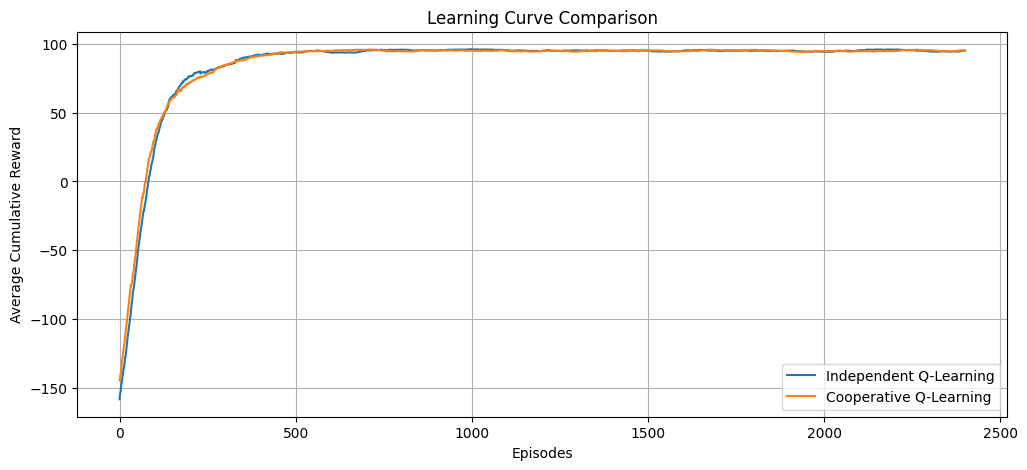

In [ ]:
#Exercise 5 – Visualization
def moving_average(data, window=100):

    return np.convolve(
        data,
        np.ones(window) / window,
        mode="valid"
    )


plt.figure(figsize=(12, 5))

plt.plot(
    moving_average(independent_rewards),
    label="Independent Q-Learning"
)

plt.plot(
    moving_average(cooperative_rewards),
    label="Cooperative Q-Learning"
)

plt.xlabel("Episodes")
plt.ylabel("Average Cumulative Reward")
plt.title("Learning Curve Comparison")

plt.legend()
plt.grid()
plt.show()

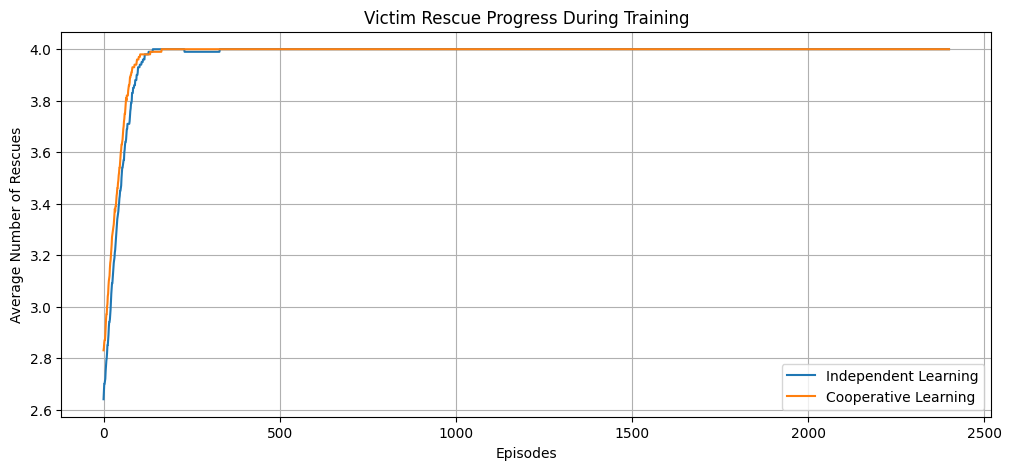

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(
    moving_average(independent_rescues),
    label="Independent Learning"
)

plt.plot(
    moving_average(cooperative_rescues),
    label="Cooperative Learning"
)

plt.xlabel("Episodes")
plt.ylabel("Average Number of Rescues")
plt.title("Victim Rescue Progress During Training")

plt.legend()
plt.grid()
plt.show()

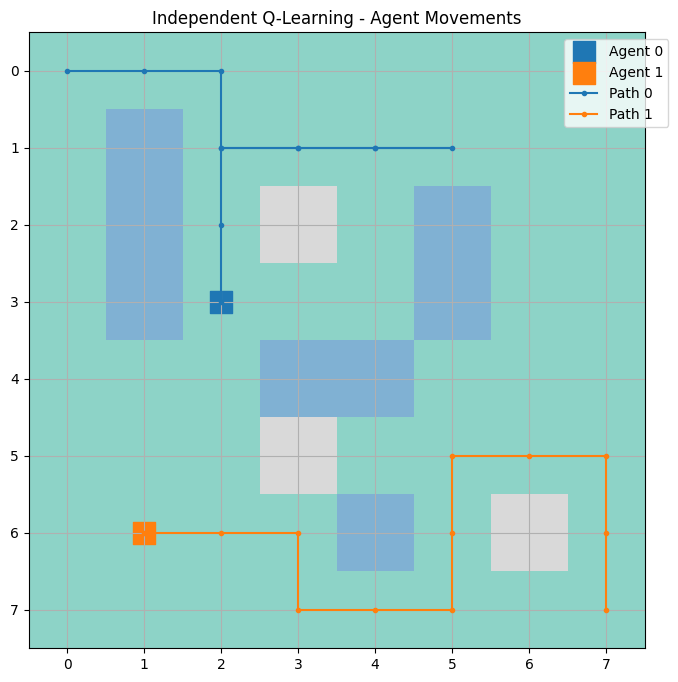

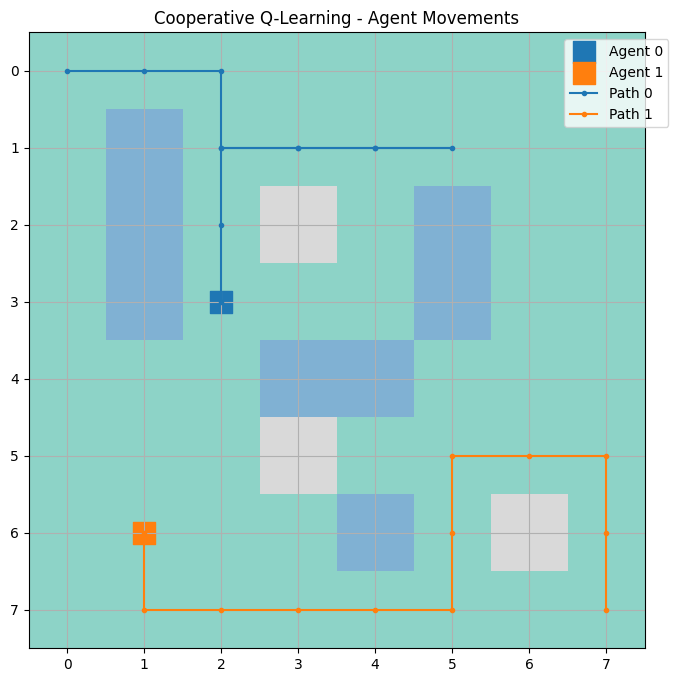

In [ ]:
def run_simulation(q_table, shared=False):

    positions = START_POSITIONS.copy()

    rescued = set()

    trajectories = {
        0: [positions[0]],
        1: [positions[1]]
    }

    total_reward = 0
    collisions = 0
    steps = 0

    while len(rescued) < len(VICTIMS) and steps < 120:

        for agent in [0, 1]:

            target = get_next_target(agent, rescued)

            if target is None:
                continue

            state = get_state(
                positions[agent],
                target
            )

            if shared:
                action = int(np.argmax(q_table[state]))
            else:
                action = int(np.argmax(q_table[agent][state]))

            reward, rescued_now, collision = environment_step(
                agent,
                action,
                positions,
                rescued
            )

            total_reward += reward
            collisions += int(collision)

            steps += 1

            trajectories[agent].append(
                positions[agent]
            )

            if len(rescued) == len(VICTIMS) or steps >= 120:
                break

    return {
        "rescued": len(rescued),
        "reward": total_reward,
        "steps": steps,
        "collisions": collisions,
        "trajectories": trajectories,
        "rescued_ids": rescued
    }


independent_sim = run_simulation(
    independent_q,
    shared=False
)

cooperative_sim = run_simulation(
    cooperative_q,
    shared=True
)

draw_environment(
    positions={
        0: independent_sim["trajectories"][0][-1],
        1: independent_sim["trajectories"][1][-1]
    },
    rescued=independent_sim["rescued_ids"],
    trajectories=independent_sim["trajectories"],
    title="Independent Q-Learning - Agent Movements"
)

draw_environment(
    positions={
        0: cooperative_sim["trajectories"][0][-1],
        1: cooperative_sim["trajectories"][1][-1]
    },
    rescued=cooperative_sim["rescued_ids"],
    trajectories=cooperative_sim["trajectories"],
    title="Cooperative Q-Learning - Agent Movements"
)

In [ ]:
#Exercise 6 – Performance Evaluation
evaluation_df = pd.DataFrame({

    "Metric": [
        "Successful Rescues",
        "Completion Time",
        "Cumulative Reward",
        "Collisions"
    ],

    "Independent Q-Learning": [
        independent_sim["rescued"],
        independent_sim["steps"],
        independent_sim["reward"],
        independent_sim["collisions"]
    ],

    "Cooperative Q-Learning": [
        cooperative_sim["rescued"],
        cooperative_sim["steps"],
        cooperative_sim["reward"],
        cooperative_sim["collisions"]
    ]

})

display(evaluation_df)

,Metric,Independent Q-Learning,Cooperative Q-Learning
0,Successful Rescues,4,4
1,Completion Time,22,22
2,Cumulative Reward,98,98
3,Collisions,0,0


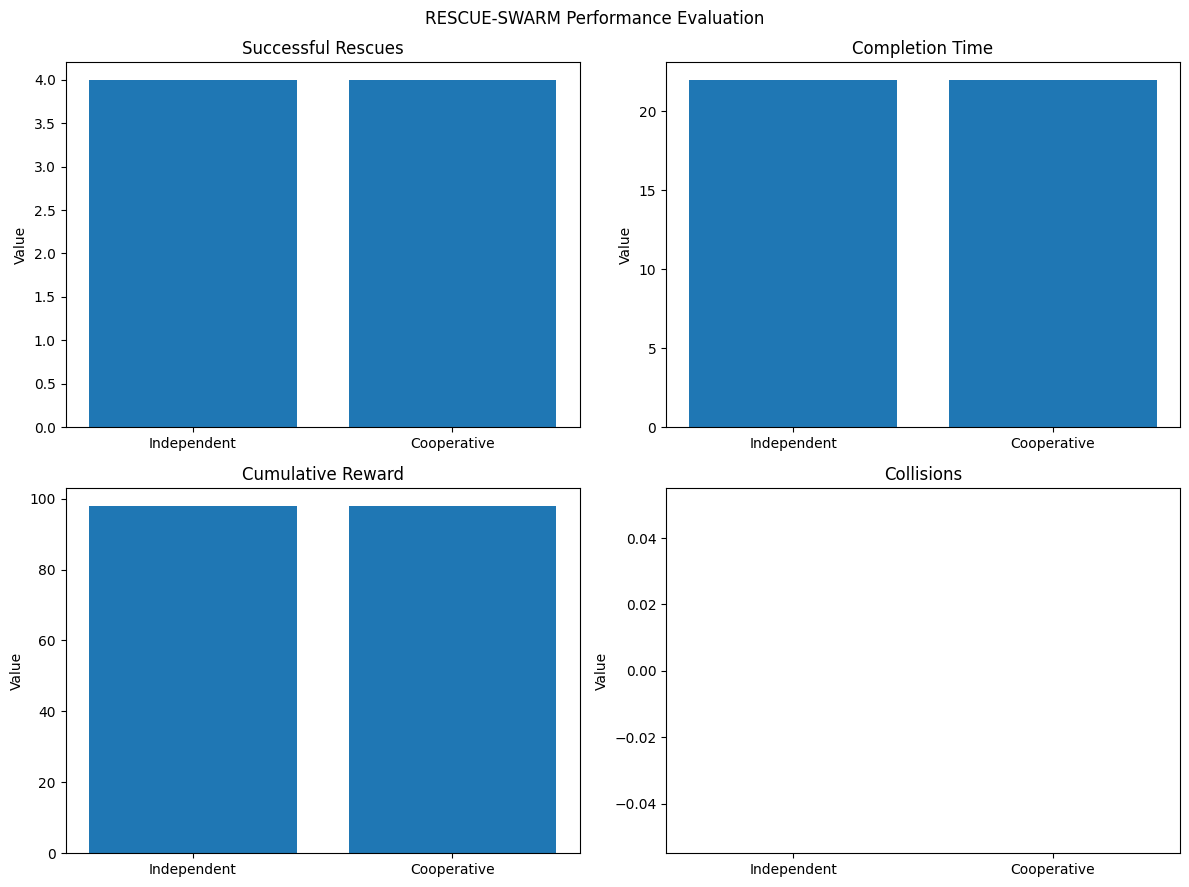

In [ ]:
metrics = [
    "Successful Rescues",
    "Completion Time",
    "Cumulative Reward",
    "Collisions"
]

independent_values = [
    independent_sim["rescued"],
    independent_sim["steps"],
    independent_sim["reward"],
    independent_sim["collisions"]
]

cooperative_values = [
    cooperative_sim["rescued"],
    cooperative_sim["steps"],
    cooperative_sim["reward"],
    cooperative_sim["collisions"]
]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for i, ax in enumerate(axes.flat):

    ax.bar(
        ["Independent", "Cooperative"],
        [
            independent_values[i],
            cooperative_values[i]
        ]
    )

    ax.set_title(metrics[i])
    ax.set_ylabel("Value")

plt.suptitle("RESCUE-SWARM Performance Evaluation")

plt.tight_layout()
plt.show()

In [ ]:
print("=" * 55)
print("       RESCUE-SWARM - FINAL EXPERIMENT REPORT")
print("=" * 55)

print("\nINDEPENDENT Q-LEARNING")

print("Victims Rescued:", independent_sim["rescued"])
print("Completion Time:", independent_sim["steps"])
print("Cumulative Reward:", independent_sim["reward"])
print("Collisions:", independent_sim["collisions"])

print("\nCOOPERATIVE Q-LEARNING")

print("Victims Rescued:", cooperative_sim["rescued"])
print("Completion Time:", cooperative_sim["steps"])
print("Cumulative Reward:", cooperative_sim["reward"])
print("Collisions:", cooperative_sim["collisions"])

print("\nCONCLUSION")

if cooperative_sim["rescued"] > independent_sim["rescued"]:
    print("Cooperative learning rescued more victims.")

elif cooperative_sim["rescued"] == independent_sim["rescued"]:
    print("Both approaches rescued the same number of victims.")

else:
    print("Independent learning rescued more victims.")

print("\nExperiment 12 completed successfully!")
print("=" * 55)

       RESCUE-SWARM - FINAL EXPERIMENT REPORT

INDEPENDENT Q-LEARNING
Victims Rescued: 4
Completion Time: 22
Cumulative Reward: 98
Collisions: 0

COOPERATIVE Q-LEARNING
Victims Rescued: 4
Completion Time: 22
Cumulative Reward: 98
Collisions: 0

CONCLUSION
Both approaches rescued the same number of victims.

Experiment 12 completed successfully!
